In [1]:
import numpy as np

# 1. Corpus
corpus = [
    "cats like milk",
    "cats drink milk",
    "dogs like milk",
    "dogs chase balls",
    "cats chase balls"
]

# 2. Build vocabulary
sentences = [s.split() for s in corpus]
vocab = sorted(set(word for s in sentences for word in s))

word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

V = len(vocab)
print("Vocabulary:", vocab)

# Hyperparameters
window = 1
d = 3
learning_rate = 0.05
epochs = 500

# 3. Generate center-context training pairs
pairs = []

for sentence in sentences:
    ids = [word_to_id[w] for w in sentence]

    for i, center in enumerate(ids):
        for j in range(max(0, i - window),
                       min(len(ids), i + window + 1)):
            if i != j:
                pairs.append((center, ids[j]))

print("Training pairs:", (pairs))

Vocabulary: ['balls', 'cats', 'chase', 'dogs', 'drink', 'like', 'milk']
Training pairs: [(1, 5), (5, 1), (5, 6), (6, 5), (1, 4), (4, 1), (4, 6), (6, 4), (3, 5), (5, 3), (5, 6), (6, 5), (3, 2), (2, 3), (2, 0), (0, 2), (1, 2), (2, 1), (2, 0), (0, 2)]



Learned word embeddings:
balls [-1.266 -1.971 -1.919]
cats [ 0.009 -1.334  0.439]
chase [ 1.113  0.284 -1.355]
dogs [-1.852 -1.044  0.163]
drink [0.983 1.665 1.2  ]
like [-0.486  1.588 -0.12 ]
milk [-0.314 -0.637  2.018]


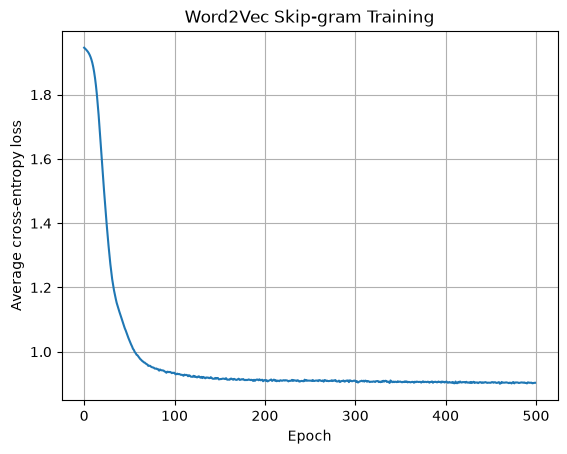

In [2]:

# 4. Initialize parameters randomly
np.random.seed(42)

E = np.random.randn(V, d) * 0.1
W = np.random.randn(d, V) * 0.1

# 5. Softmax function
def softmax(x):
    x = x - np.max(x)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x)

# 6. Train Skip-gram
losses = []

for epoch in range(epochs):
    np.random.shuffle(pairs)
    total_loss = 0

    for center, context in pairs:

        # Forward pass
        h = E[center].copy()
        scores = h @ W
        probabilities = softmax(scores)

        # Cross-entropy loss
        loss = -np.log(probabilities[context] + 1e-12)
        total_loss += loss

        # Backpropagation
        error = probabilities.copy()
        error[context] -= 1

        gradient_W = np.outer(h, error)
        gradient_h = W @ error

        # Update parameters
        W -= learning_rate * gradient_W
        E[center] -= learning_rate * gradient_h

    losses.append(total_loss / len(pairs))

# 7. Print learned embeddings
print("\nLearned word embeddings:")
for word, idx in word_to_id.items():
    print(word, np.round(E[idx], 3))

# 8. Plot training loss
import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("Word2Vec Skip-gram Training")
plt.grid(True)
plt.show()

In [3]:
def cosine_similarity(a, b):
    return np.dot(a, b) / (
        np.linalg.norm(a) * np.linalg.norm(b) + 1e-12
    )

def similar_words(word, top_k=3):
    idx = word_to_id[word]
    scores = []

    for j in range(V):
        if j != idx:
            sim = cosine_similarity(E[idx], E[j])
            scores.append((id_to_word[j], sim))

    return sorted(scores, key=lambda x: x[1], reverse=True)[:top_k]

print("Words similar to cats:", similar_words("cats"))
print("Words similar to dogs:", similar_words("dogs"))

Words similar to cats: [('milk', np.float64(0.577061012686912)), ('dogs', np.float64(0.4834203312965609)), ('balls', np.float64(0.41749560926209794))]
Words similar to dogs: [('balls', np.float64(0.6335467734426936)), ('cats', np.float64(0.4834203312965609)), ('milk', np.float64(0.3453293555661983))]
